# Lab 1 · Regression: asphaltene precipitation
**Slides:** Module 06 (algorithms) and 07 (evaluation)  ·  **Time:** 75 min

Adding an n-alkane (n-C5 … n-C12) to crude oil precipitates asphaltene. We predict the **weight percent precipitated**
from temperature, the alkane carbon number and the dilution ratio (mL alkane per g oil), and compare ten algorithms,
the same ones as the course notebooks (`Linear_Regression`, `KNN`, `SVR`, `DT`, `RF`, `AdaBoost`, `Gradient_Boosting`, `NN`, `Voting`).

**You will:** compare algorithms · tune with cross-validation instead of the test set · test on a whole unseen series · explain the model.

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("aiml"):
    print("Upload the course kit zip to Colab, then unzip it:  !unzip -q aiml_course_kit.zip && %cd aiml_course_kit")
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data" if os.path.exists("../data") else "data"

from aiml.data import load_asphaltene, ASPH_FEATURES, ASPH_TARGET
from aiml.models import regressors
from aiml.evaluate import compare, crossplot, hyper_curve, report, importance
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score
df = load_asphaltene()
X, y = df[ASPH_FEATURES], df[ASPH_TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 1 · Ten algorithms on all 167 tests

In [2]:
res_all = compare(regressors(), X_train, y_train, X_test, y_test); res_all[["model", "R2_train", "R2_test", "MAE_test", "fit_s"]]

,model,R2_train,R2_test,MAE_test,fit_s
0,Neural network (MLP),1.0000,0.9981,0.1926,3.9118
1,Voting (RF + GB + MLP),0.9987,0.8868,0.9452,4.7482
2,Extra trees,1.0000,0.8461,1.1708,0.4692
3,Gradient boosting,0.9998,0.7764,1.2155,0.3680
4,Decision tree,0.9999,0.7722,1.4584,0.0100
5,Random forest,0.9890,0.7120,1.6122,0.7513
6,AdaBoost,0.9944,0.6949,1.7744,0.3265
7,Hist. gradient boosting (XGBoost-style),0.8564,0.5712,3.1263,6.2622
8,KNN,1.0000,0.5509,2.3143,0.0120
9,SVR,0.7923,0.4451,2.6799,0.0251


## 2 · The same comparison without the 17 suspect tests (Lab 0)

In [3]:
clean = load_asphaltene(drop_suspect=True)
Xc, yc = clean[ASPH_FEATURES], clean[ASPH_TARGET]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42)
res_clean = compare(regressors(), Xc_train, yc_train, Xc_test, yc_test)
res_all[["model", "R2_test"]].merge(res_clean[["model", "R2_test"]], on="model", suffixes=("_all", "_clean"))

,model,R2_test_all,R2_test_clean
0,Neural network (MLP),0.9981,0.9894
1,Voting (RF + GB + MLP),0.8868,0.9828
2,Extra trees,0.8461,0.9806
3,Gradient boosting,0.7764,0.9751
4,Decision tree,0.7722,0.9365
5,Random forest,0.7120,0.9571
6,AdaBoost,0.6949,0.9298
7,Hist. gradient boosting (XGBoost-style),0.5712,0.9594
8,KNN,0.5509,0.8971
9,SVR,0.4451,0.9863


Seventeen rows decide the ranking. With them, only flexible models (trees, neural nets) can chase the three extreme
series and linear regression fails; without them, even linear regression reaches R² ≈ 0.96. **Clean data first,
then choose the algorithm.** We continue with the clean data.

## 3 · Tuning: the course loops, done safely
The course notebooks loop over `max_depth` or `n_neighbors` and pick the value with the best **test** score. That uses
the test set to make a decision, so the test score is no longer an honest estimate. Use cross-validation on the
training data to tune, and touch the test set once at the end.

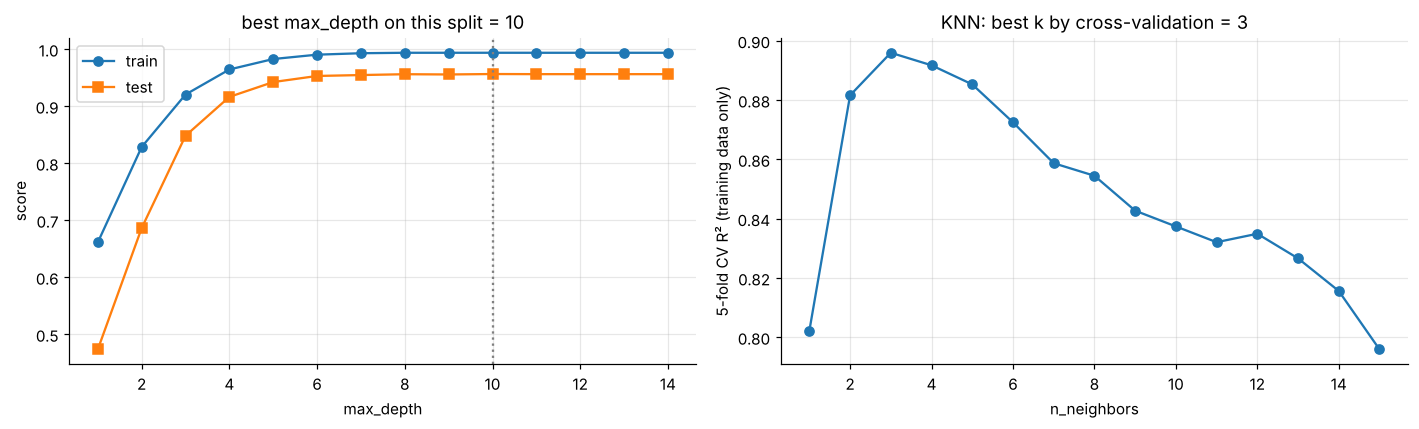

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hyper_curve(RandomForestRegressor(n_estimators=100, random_state=0), "max_depth", list(range(1, 15)), Xc_train, yc_train, Xc_test, yc_test, ax=ax[0])
cv = KFold(5, shuffle=True, random_state=0)
ks = list(range(1, 16))
cv_scores = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsRegressor(k)), Xc_train, yc_train, cv=cv).mean() for k in ks]
ax[1].plot(ks, cv_scores, "o-"); ax[1].set_xlabel("n_neighbors"); ax[1].set_ylabel("5-fold CV R² (training data only)")
ax[1].set_title(f"KNN: best k by cross-validation = {ks[int(np.argmax(cv_scores))]}"); plt.tight_layout(); plt.show()

### ✏️ Your turn 1
Tune `C` of the SVR (`regressors()["SVR"]`, parameter name `svr__C`) over `[0.3, 1, 3, 10, 30, 100, 300]` with 5-fold
cross-validation on the training data. Then fit the best one and report the test score once.

In [5]:
svr = regressors()["SVR"]
Cs = [0.3, 1, 3, 10, 30, 100, 300]
s = [cross_val_score(svr.set_params(svr__C=c), Xc_train, yc_train, cv=cv).mean() for c in Cs]
best = Cs[int(np.argmax(s))]; print(dict(zip(Cs, np.round(s, 3))), "→ best C =", best)
svr.set_params(svr__C=best).fit(Xc_train, yc_train); report(yc_test, svr.predict(Xc_test), "SVR test (once)")

{0.3: np.float64(0.841), 1: np.float64(0.93), 3: np.float64(0.962), 10: np.float64(0.974), 30: np.float64(0.977), 100: np.float64(0.975), 300: np.float64(0.975)} → best C = 30
SVR test (once)              R2 0.986  MAE 0.171  RMSE 0.212  MAPE 8.9%


{'R2': 0.9863491749364528,
 'MAE': 0.17068091729499282,
 'RMSE': 0.2117234450185667,
 'MAPE_%': np.float64(8.895759400935118)}

## 4 · A harder, more honest test: unseen series
A random split puts points of the same curve in train and test, so the model only interpolates along a curve it
already saw. In practice you want to predict a **new temperature or a new precipitant**. `GroupKFold` holds out whole
series (one temperature + n-alkane curve at a time).

In [6]:
groups = clean["series"]
rows = []
for name, m in regressors().items():
    p_rand = cross_val_predict(m, Xc, yc, cv=KFold(5, shuffle=True, random_state=0))
    p_grp = cross_val_predict(m, Xc, yc, cv=GroupKFold(5), groups=groups)
    rows.append({"model": name, "random 5-fold R²": r2_score(yc, p_rand), "unseen-series R²": r2_score(yc, p_grp)})
pd.DataFrame(rows).sort_values("unseen-series R²", ascending=False).round(3)

,model,random 5-fold R²,unseen-series R²
11,Voting (RF + GB + MLP),0.983,0.969
8,Gradient boosting,0.977,0.965
1,Polynomial (deg 2),0.963,0.964
6,Extra trees,0.973,0.957
10,Neural network (MLP),0.989,0.957
3,SVR,0.983,0.947
5,Random forest,0.954,0.940
9,Hist. gradient boosting (XGBoost-style),0.956,0.936
2,KNN,0.894,0.926
7,AdaBoost,0.941,0.918


### ✏️ Your turn 2 · physics features
Precipitation grows roughly with the **logarithm** of dilution. Add `log_dilution` (`load_asphaltene(drop_suspect=True, add_features=True)`)
and repeat the unseen-series test for *Linear regression*, *KNN* and *Neural network (MLP)*. Which model gains most, and why?

In [7]:
cf = load_asphaltene(drop_suspect=True, add_features=True)
F2 = ASPH_FEATURES + ["log_dilution"]
for name in ["Linear regression", "KNN", "Neural network (MLP)"]:
    m = regressors()[name]
    a = r2_score(yc, cross_val_predict(m, Xc, yc, cv=GroupKFold(5), groups=groups))
    b = r2_score(cf[ASPH_TARGET], cross_val_predict(m, cf[F2], cf[ASPH_TARGET], cv=GroupKFold(5), groups=cf["series"]))
    print(f"{name:<24} without {a:.3f}  with log_dilution {b:.3f}")
print("Linear regression gains most: a straight line cannot bend, the log feature bends it for the model.")

Linear regression        without 0.848  with log_dilution 0.962
KNN                      without 0.926  with log_dilution 0.945


Neural network (MLP)     without 0.957  with log_dilution 0.976
Linear regression gains most: a straight line cannot bend, the log feature bends it for the model.


## 5 · Final model, cross-plot and explanation

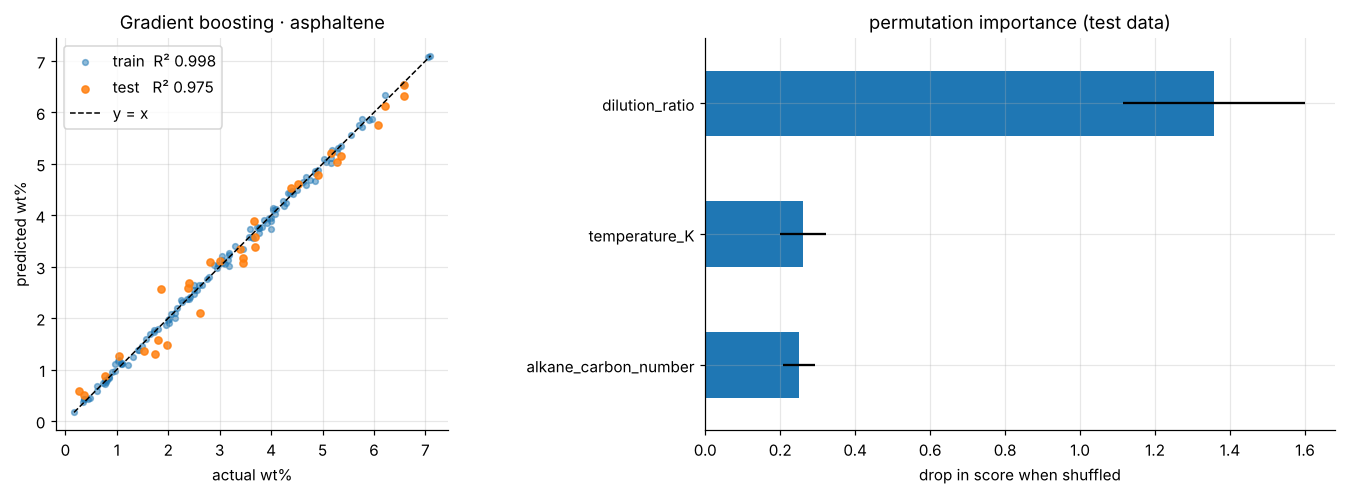

In [8]:
best = regressors()["Gradient boosting"].fit(Xc_train, yc_train)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
crossplot(yc_train, best.predict(Xc_train), yc_test, best.predict(Xc_test), "Gradient boosting · asphaltene", "wt%", ax=ax[0])
imp = importance(best, Xc_test, yc_test, ax=ax[1]); ax[1].set_title("permutation importance (test data)"); plt.tight_layout(); plt.show()

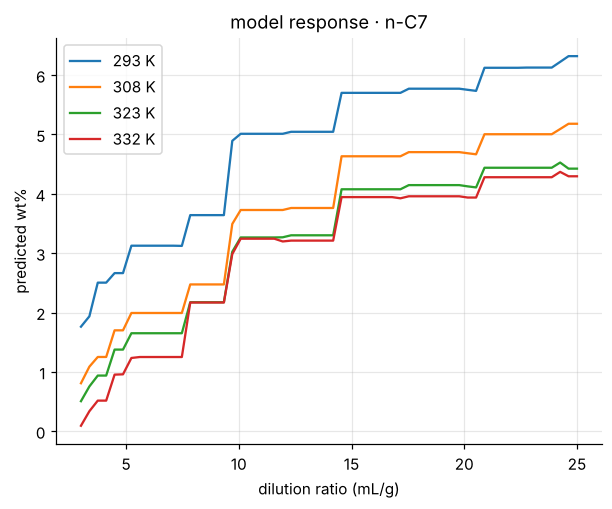

In [9]:
# what-if: precipitation curves the model predicts for n-heptane at four temperatures
dr = np.linspace(3, 25, 60)
for T in [293, 308, 323, 332]:
    plt.plot(dr, best.predict(pd.DataFrame({"temperature_K": T, "alkane_carbon_number": 7, "dilution_ratio": dr})), label=f"{T} K")
plt.xlabel("dilution ratio (mL/g)"); plt.ylabel("predicted wt%"); plt.title("model response · n-C7"); plt.legend(); plt.show()

### ✏️ Your turn 3
Look at the 332 K curve. Is it smooth and physical between the points the model saw? Tree ensembles predict in **steps**;
try `regressors()["Neural network (MLP)"]` or `"SVR"` and compare the shape. Which would you trust for a new dilution ratio?

## Key ideas
* Data quality (17 rows) changed the winner more than any algorithm choice.
* Tune with cross-validation on training data; use the test set once.
* Split the way the model will be used: unseen series is harder and more honest than a random split.
* A simple physics feature (log dilution) can make a simple model as good as a complex one.

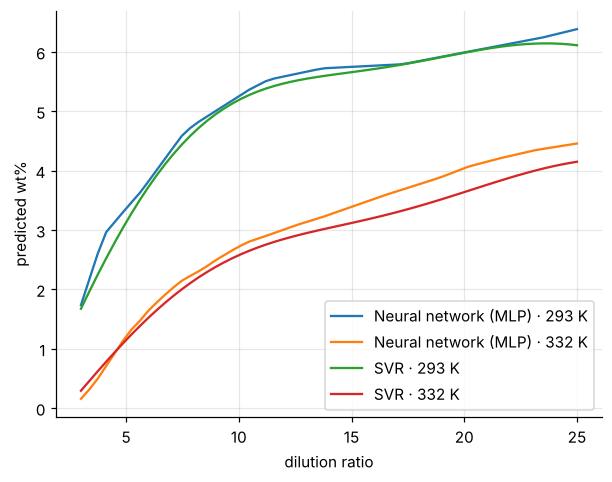

In [10]:
for name in ["Neural network (MLP)", "SVR"]:
    m = regressors()[name].fit(Xc_train, yc_train)
    for T in [293, 332]:
        plt.plot(dr, m.predict(pd.DataFrame({"temperature_K": T, "alkane_carbon_number": 7, "dilution_ratio": dr})), label=f"{name} · {T} K")
plt.xlabel("dilution ratio"); plt.ylabel("predicted wt%"); plt.legend(); plt.show()